# Quantum vs a classical baseline

Simple plots of the results already on disk -- nothing is trained here.

**Classical baseline** = the *same* detector / head, trained on the raw input
features instead of the reservoir readout. Only the feature map differs, so the
gap between the two lines is what the quantum reservoir adds.
IsolationForest on the raw features is drawn as a fixed reference.

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve()
REPO = REPO.parent if REPO.name == "notebooks" else REPO
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
from elements.eval.results import load_results

nov = load_results(REPO / "runs" / "novelty_ladder", keep=("per_type",))
print(len(nov), "novelty results")

35 novelty results


## 1. Zero-day detection (novelty ladder)

Each step makes the reservoir and the autoencoder bigger together. For every
step we take the quantum readout and the raw features, both with that step's
autoencoder.

In [2]:
scaled = nov[nov.head_role == "scaled"]
steps = (scaled[scaled.arm == "quantum"].sort_values("step")
         [["step", "config", "feature_dim", "head"]].reset_index(drop=True))

rows = []
for _, st in steps.iterrows():
    q = nov[(nov.arm == "quantum") & (nov.config == st.config) & (nov["head"] == st["head"])].iloc[0]
    r = nov[(nov.arm == "raw") & (nov["head"] == st["head"])].iloc[0]
    rows.append({"step": f"{st.config}\n{st['head']}",
                 "q_auc": q.macro_auc, "raw_auc": r.macro_auc,
                 "q_det": q["det@0.01"], "raw_det": r["det@0.01"]})
iforest = nov[nov["head"] == "iforest"].iloc[0]

for r in rows:
    print(f"{r['step'].replace(chr(10), ' '):22s} quantum AUC {r['q_auc']:.3f}  raw AUC {r['raw_auc']:.3f}"
          f"   quantum det@1% {r['q_det']:.3f}  raw det@1% {r['raw_det']:.3f}")
print(f"IsolationForest (raw): AUC {iforest.macro_auc:.3f}  det@1% {iforest['det@0.01']:.3f}")

3p12m ae128-b16        quantum AUC 0.962  raw AUC 0.969   quantum det@1% 0.854  raw det@1% 0.876
3p20m ae256-b32        quantum AUC 0.972  raw AUC 0.977   quantum det@1% 0.863  raw det@1% 0.937
3p24m ae512-b32        quantum AUC 0.974  raw AUC 0.979   quantum det@1% 0.929  raw det@1% 0.942
4p20m ae1024-b64       quantum AUC 0.976  raw AUC 0.980   quantum det@1% 0.935  raw det@1% 0.920
4p24m ae2048-b64       quantum AUC 0.977  raw AUC 0.977   quantum det@1% 0.939  raw det@1% 0.903
IsolationForest (raw): AUC 0.917  det@1% 0.798


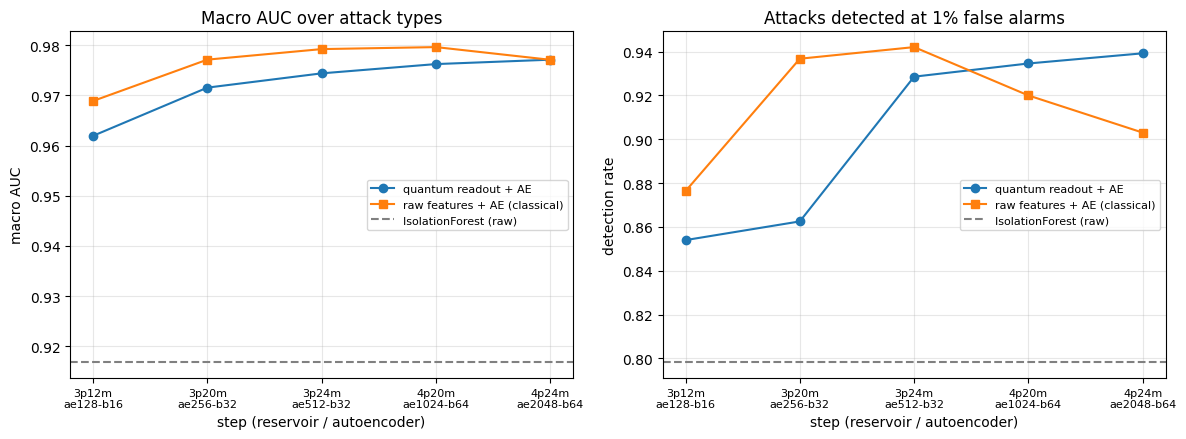

In [3]:
x = np.arange(len(rows))
labels = [r["step"] for r in rows]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(x, [r["q_auc"] for r in rows], "o-", label="quantum readout + AE")
axes[0].plot(x, [r["raw_auc"] for r in rows], "s-", label="raw features + AE (classical)")
axes[0].axhline(iforest.macro_auc, color="gray", ls="--", label="IsolationForest (raw)")
axes[0].set_title("Macro AUC over attack types")
axes[0].set_ylabel("macro AUC")

axes[1].plot(x, [r["q_det"] for r in rows], "o-", label="quantum readout + AE")
axes[1].plot(x, [r["raw_det"] for r in rows], "s-", label="raw features + AE (classical)")
axes[1].axhline(iforest["det@0.01"], color="gray", ls="--", label="IsolationForest (raw)")
axes[1].set_title("Attacks detected at 1% false alarms")
axes[1].set_ylabel("detection rate")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_xlabel("step (reservoir / autoencoder)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Per attack type, at the largest step

Detection rate at 1% false alarms for every attack type with at least 20 rows.

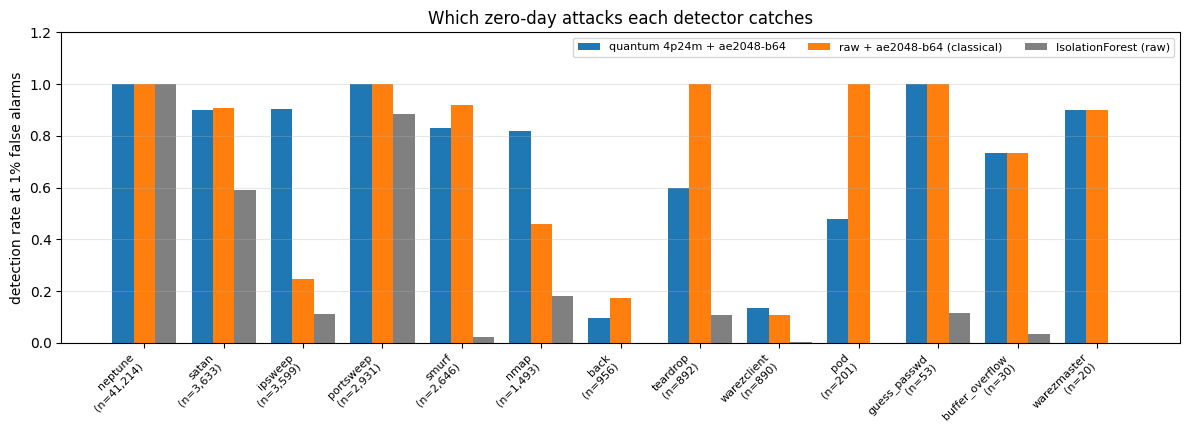

In [4]:
last = steps.iloc[-1]
q = nov[(nov.arm == "quantum") & (nov.config == last.config) & (nov["head"] == last["head"])].iloc[0]
r = nov[(nov.arm == "raw") & (nov["head"] == last["head"])].iloc[0]

attacks = [a for a, v in sorted(q.per_type.items(), key=lambda kv: -kv[1]["n"]) if v["n"] >= 20]
q_det = [q.per_type[a]["det@0.01"] for a in attacks]
r_det = [r.per_type[a]["det@0.01"] for a in attacks]
if_det = [iforest.per_type[a]["det@0.01"] for a in attacks]

x = np.arange(len(attacks))
w = 0.27
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x - w, q_det, w, label=f"quantum {last.config} + {last['head']}")
ax.bar(x, r_det, w, label=f"raw + {last['head']} (classical)")
ax.bar(x + w, if_det, w, label="IsolationForest (raw)", color="gray")
ax.set_xticks(x)
ax.set_xticklabels([f"{a}\n(n={q.per_type[a]['n']:,})" for a in attacks], rotation=45,
                   ha="right", fontsize=8)
ax.set_ylabel("detection rate at 1% false alarms")
ax.set_ylim(0, 1.2)
ax.set_title("Which zero-day attacks each detector catches")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, ncol=3, loc="upper right")
plt.tight_layout()
plt.show()

## 3. Supervised classification (joint scaling grid, first sweep)

macro-F1 for each head size: the largest reservoir (4p24m, 10,626 features)
vs the same head on the raw features. A fixed config is compared on purpose --
taking the best of five reservoirs on the test set would flatter the quantum
side. Read from `runs/joint_scaling`.

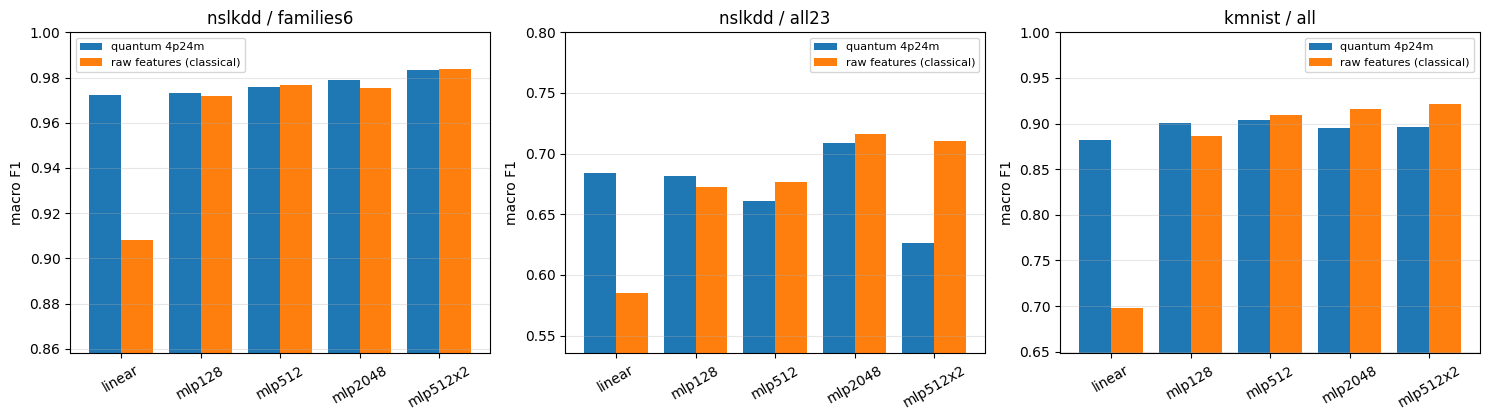

In [5]:
sup = load_results(REPO / "runs" / "joint_scaling")
heads = ["linear", "mlp128", "mlp512", "mlp2048", "mlp512x2"]
panels = [("nslkdd", "families6"), ("nslkdd", "all23"), ("kmnist", "all")]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (ds, sc) in zip(axes, panels):
    s = sup[(sup.dataset == ds) & (sup.scheme == sc)]
    best_q = [s[(s.arm == "quantum") & (s.config == "4p24m") & (s["head"] == h)].macro_f1.iloc[0]
              for h in heads]
    raw = [s[(s.arm == "raw") & (s["head"] == h)].macro_f1.iloc[0] for h in heads]
    x = np.arange(len(heads))
    ax.bar(x - 0.2, best_q, 0.4, label="quantum 4p24m")
    ax.bar(x + 0.2, raw, 0.4, label="raw features (classical)")
    lo = min(min(best_q), min(raw))
    ax.set_ylim(lo - 0.05, 1.0 if ds != "nslkdd" or sc != "all23" else 0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(heads, rotation=30)
    ax.set_title(f"{ds} / {sc}")
    ax.set_ylabel("macro F1")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Quantum vs standalone classical detectors (zero-day)

Every classical detector here is trained on the raw features alone, on the same
normal-only rows, and scored on the same test rows (`runs/classical_novelty`).
The quantum side is fixed in advance, not picked on the test set: the largest
ladder step (4p24m + its autoencoder) and the original design (4p24m + PCA-32).

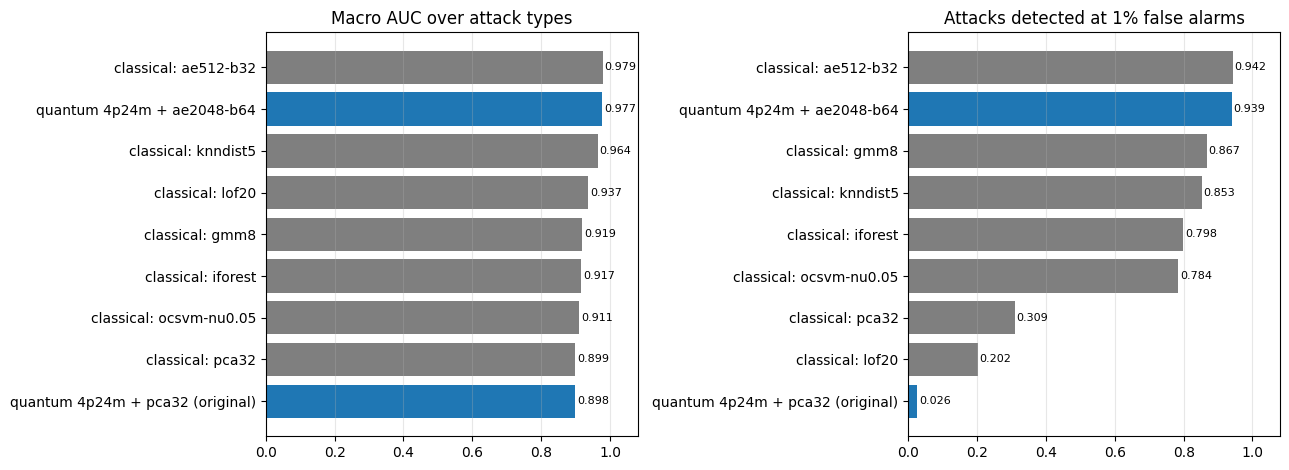

In [6]:
cls_nov = load_results(REPO / "runs" / "classical_novelty")
last = steps.iloc[-1]
entries = [(f"quantum {last.config} + {last['head']}",
            nov[(nov.arm == "quantum") & (nov.config == last.config) & (nov["head"] == last["head"])].iloc[0]),
           (f"quantum {last.config} + pca32 (original)",
            nov[(nov.arm == "quantum") & (nov.config == last.config) & (nov["head"] == "pca32")].iloc[0])]
entries += [(f"classical: {r['head']}", r) for _, r in cls_nov.iterrows()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, metric, title in [(axes[0], "macro_auc", "Macro AUC over attack types"),
                          (axes[1], "det@0.01", "Attacks detected at 1% false alarms")]:
    order = sorted(entries, key=lambda e: e[1][metric])
    names = [e[0] for e in order]
    vals = [e[1][metric] for e in order]
    colors = ["tab:blue" if n.startswith("quantum") else "tab:gray" for n in names]
    ax.barh(names, vals, color=colors)
    for y, v in enumerate(vals):
        ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=8)
    ax.set_title(title)
    ax.set_xlim(0, 1.08)
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Quantum vs standalone classical classifiers (supervised)

Classical models on the raw features (`runs/classical_supervised`) against the
largest reservoir from the joint-scaling sweep (4p24m), with the original linear
head and with an MLP 512x2. Same test rows.

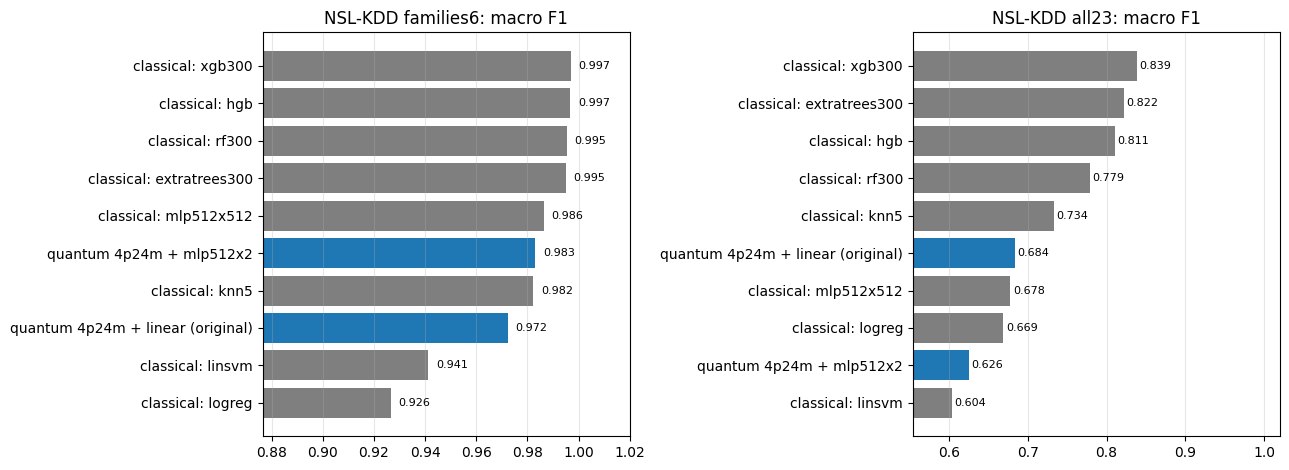

In [7]:
cls_sup = load_results(REPO / "runs" / "classical_supervised")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, sc in zip(axes, ["families6", "all23"]):
    s = sup[(sup.dataset == "nslkdd") & (sup.scheme == sc)]
    entries = [("quantum 4p24m + linear (original)",
                s[(s.arm == "quantum") & (s.config == "4p24m") & (s["head"] == "linear")].macro_f1.iloc[0]),
               ("quantum 4p24m + mlp512x2",
                s[(s.arm == "quantum") & (s.config == "4p24m") & (s["head"] == "mlp512x2")].macro_f1.iloc[0])]
    c = cls_sup[cls_sup.scheme == sc]
    entries += [(f"classical: {r['head']}", r.macro_f1) for _, r in c.iterrows()]
    entries.sort(key=lambda e: e[1])
    names = [e[0] for e in entries]
    vals = [e[1] for e in entries]
    ax.barh(names, vals, color=["tab:blue" if n.startswith("quantum") else "tab:gray" for n in names])
    for y, v in enumerate(vals):
        ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=8)
    ax.set_xlim(min(vals) - 0.05, 1.02)
    ax.set_title(f"NSL-KDD {sc}: macro F1")
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Per-attack table (zero-day)

Share of each attack type caught at a 1% false-alarm budget (threshold set on
normal traffic only), for the quantum detectors and every classical detector.
The last two rows are the mean over attack types with at least 20 rows and the
pooled rate over all attack rows. Types with only a handful of rows are kept
for completeness, but their percentages are luck, not measurement.
Also written to `runs/comparison/` as CSV and Excel.

In [8]:
import pandas as pd
from elements.viz.novelty import attack_comparison

cls_nov = load_results(REPO / "runs" / "classical_novelty", keep=("per_type",))
def pick(df, **kw):
    m = np.ones(len(df), bool)
    for k, v in kw.items():
        m &= (df[k] == v).to_numpy()
    return df[m].iloc[0]

models = {
    "Q 4p24m+AE2048": pick(nov, arm="quantum", config="4p24m", head="ae2048-b64"),
    "Q 4p24m+PCA32 (orig)": pick(nov, arm="quantum", config="4p24m", head="pca32"),
    "AE512 (raw)": pick(cls_nov, head="ae512-b32"),
    "kNN-dist5": pick(cls_nov, head="knndist5"),
    "GMM8": pick(cls_nov, head="gmm8"),
    "IsolationForest": pick(cls_nov, head="iforest"),
    "OC-SVM": pick(cls_nov, head="ocsvm-nu0.05"),
    "LOF20": pick(cls_nov, head="lof20"),
    "PCA32 (raw)": pick(cls_nov, head="pca32"),
}
det = attack_comparison(models, "det@0.01")
auc = attack_comparison(models, "auc")

out = REPO / "runs" / "comparison"
out.mkdir(exist_ok=True)
det.to_csv(out / "novelty_per_attack_detection_at_1pct_FA.csv", float_format="%.4f")
auc.to_csv(out / "novelty_per_attack_auc.csv", float_format="%.4f")
with pd.ExcelWriter(out / "novelty_per_attack_comparison.xlsx") as xw:
    det.round(4).to_excel(xw, sheet_name="detection@1%FA")
    auc.round(4).to_excel(xw, sheet_name="AUC")

pct = det.copy()
pct[list(models)] = (pct[list(models)] * 100).round(1)
pct

,category,n,Q 4p24m+AE2048,Q 4p24m+PCA32 (orig),AE512 (raw),kNN-dist5,GMM8,IsolationForest,OC-SVM,LOF20,PCA32 (raw)
neptune,DoS,41214,100.0,2.5,100.0,100.0,98.5,100.0,92.5,17.5,41.5
smurf,DoS,2646,83.0,0.0,90.9,73.8,94.4,2.1,62.2,68.9,0.0
back,DoS,956,9.5,0.5,17.6,9.4,15.8,0.0,9.4,2.7,0.5
teardrop,DoS,892,59.8,0.0,99.4,11.3,100.0,10.5,7.0,34.4,0.0
pod,DoS,201,47.8,36.8,66.2,23.9,100.0,0.0,11.4,20.4,1.5
land,DoS,18,55.6,0.0,72.2,100.0,100.0,100.0,100.0,100.0,100.0
satan,Probe,3633,90.1,0.5,83.6,67.7,73.3,58.9,57.0,27.1,0.6
ipsweep,Probe,3599,90.2,0.5,83.4,20.0,23.1,11.0,19.0,22.3,0.9
portsweep,Probe,2931,99.9,1.1,99.9,99.8,82.1,88.5,96.8,6.5,20.1
nmap,Probe,1493,81.8,17.4,81.8,18.2,27.0,18.1,17.9,20.7,17.7


In [9]:
auc.loc[["MEAN over types (n>=20)", "POOLED (all attack rows)"]].round(3)

,category,n,Q 4p24m+AE2048,Q 4p24m+PCA32 (orig),AE512 (raw),kNN-dist5,GMM8,IsolationForest,OC-SVM,LOF20,PCA32 (raw)
MEAN over types (n>=20),,58558,0.977,0.898,0.979,0.964,0.919,0.917,0.911,0.937,0.899
POOLED (all attack rows),,58630,0.995,0.946,0.995,0.991,0.969,0.983,0.977,0.952,0.962


**Reading these plots** (one seed: gaps under ~0.02 are within noise).

* **Zero-day detection:** quantum 4p24m + autoencoder is level with the best
  classical detector, an autoencoder on the raw features (0.939 vs 0.942
  detected at 1% false alarms; macro AUC 0.977 vs 0.979), and ahead of GMM,
  kNN-distance, IsolationForest, one-class SVM, LOF and PCA. It leads on the
  Probe attacks (ipsweep, nmap, satan); GMM and the raw autoencoder catch the
  small DoS attacks (teardrop, pod) far better. The original quantum + PCA-32
  design catches almost nothing at this budget despite an AUC of ~0.90.
* **Supervised classification:** gradient-boosted and random-forest trees on
  the raw features win clearly (XGBoost 0.997 families6, 0.839 all23) over the
  best fixed quantum setting (0.983 / 0.684). The reservoir beats the linear
  classical models, not the strong ones.